# A PROJECT TO ANALYSE AND BUILD MODELS TO RECOMMEND ON MENTAL HEALTH CHALLENGES TREATMENT
   ## Project Overview
   ###  Problem Statement
- **Numerous cases of mental health challenges** have been encountered across various countries in the world.
   Due to various circumstances circulating people across the the world. 
- Extreme cases of mental health challenges *leads to abnormal functioning of human being causing madness and 
   sometimes causes death in severe cases.*

  ### Aim of Project
- *Analysing circumstances surrounding people* across various regions of the world under which some victim people 
   contractmental health infections.
- Building up insights ,creating and employing the *appropriate criterias* to curb various mental-health-causing 
   circumstances circulating people's lives.
- Creating Various activities *involving many people together to bring people from their various day activities for 
   consultation and creating awareness.*

  ### Data Understanding
- *My mental health dataset* is from [kaggle](https://www.kaggle.com/datasets/bhavikjikadara/mental-health-dataset)
- *It has got *sixteen* columns*
- **Gender** - indication of either a patient is Male or Female
- **Country** - a nation to the patient belongs to
- **Occupation** - the job the patinet was doing
- **SelfEmployed** - an indication whether a patient was self-employed (Yes/No) or not sure
- **FamilyHistory** - A trace mental health challenge in the patient's family (Yes/No) or not sure 
- **Treatment** - confirming whether the patient received Treatment (Yes/No) or not sure
- **DaysIndoors** - number of days the patient stayed locked in given premises
- **HabitsChange** -an indication if there was change in behavior of the patient (Yes/No) or not sure
- **MentalHealthHistory** - previous traces of mental health challenges(Yes/No) or not sure
- **IncreasingStress** - rise in stress levels (Yes/No) or not sure
- **MoodSwings** - refers to shift of the mood (High/Medium/low)
- **SocialWeakness** - shortcomings in terms of social life(Yes/No) or not sure
- **CopingStruggles** - improvements witnessed (Yes/No) 
- **WorkInterest** - patient building up a working interest (Yes/Not) or not sure
- **MentalHealthInterview** - record of if ever had a mental health interview (Yes/No) or not sure
- **CareOptions** - care options the patient (Yes/No) or not sure


  ### The flow of the project
1. **Data cleaning** 
- removing duplicate columns
- dropping duplicates
- filling empty cells
2. **feature engineering**
3. **data visualization**
4. **Modelling using supervised machine learning**
5. **Valuation Metrics**
6. **Conclusions**
7. **Recommendations**


In [1]:
import pandas as pd
import numpy as np

In [2]:
fd=pd.read_csv("Mental Health dataset1.csv")

In [3]:
fd.head()

,Gender,Country,Occupation,SelfEmployed,FamilyHistory,Treatment,DaysIndoors,HabitsChange,MentalHealthHistory,IncreasingStress,MoodSwings,SocialWeakness,CopingStruggles,WorkInterest,SocialWeakness.1,MentalHealthInterview,CareOptions
0,Female,UK,Others,No,Yes,No,15-30 days,No,Yes,Yes,High,No,Yes,Maybe,No,No,No
1,Female,USA,Housewife,No,Yes,No,15-30 days,Maybe,Maybe,Yes,High,Maybe,Yes,Maybe,Maybe,No,Not sure
2,Female,Canada,Others,No,No,Yes,More than 2 months,Maybe,No,No,Medium,No,No,No,No,No,Not sure
3,Female,Canada,Corporate,No,Yes,Yes,Go out Every day,No,Maybe,No,Medium,No,No,Maybe,No,No,Not sure
4,Female,UK,Corporate,No,No,Yes,More than 2 months,Yes,No,Maybe,Medium,Maybe,No,Maybe,Maybe,No,Not sure


In [4]:
fd["Country"].unique()

<StringArray>
[                    'UK',                    'USA',                 'Canada',
            'New Zealand',              'Australia',                 'Poland',
           'South Africa',                'Ireland',                'Belgium',
            'Netherlands',                  'India',                 'Sweden',
                 'Brazil', 'Bosnia and Herzegovina',               'Colombia',
             'Costa Rica',                'Croatia',         'Czech Republic',
                'Denmark',                'Finland',                 'France',
                'Georgia',                'Germany',                 'Greece',
                 'Israel',                  'Italy',                 'Mexico',
                'Moldova',                'Nigeria',            'Philippines',
               'Portugal',                 'Russia',              'Singapore',
            'Switzerland',               'Thailand']
Length: 35, dtype: str

In [5]:
print(fd.columns.tolist())

['Gender', 'Country', 'Occupation', 'SelfEmployed', 'FamilyHistory', 'Treatment', 'DaysIndoors', 'HabitsChange', 'MentalHealthHistory', 'IncreasingStress', 'MoodSwings', 'SocialWeakness', 'CopingStruggles', 'WorkInterest', 'SocialWeakness.1', 'MentalHealthInterview', 'CareOptions']


## Data Cleaning

In [6]:
print(fd["SocialWeakness"] == fd["SocialWeakness.1"])

0         True
1         True
2         True
3         True
4         True
          ... 
261323    True
261324    True
261325    True
261326    True
261327    True
Length: 261328, dtype: bool


In [7]:
fd=fd.drop(columns=["SocialWeakness.1"])

In [8]:
fd["Gender"].unique()

<StringArray>
['Female', 'Male']
Length: 2, dtype: str

In [9]:
fd.isnull().sum()

Gender                      0
Country                     0
Occupation                  0
SelfEmployed             4356
FamilyHistory               0
Treatment                   0
DaysIndoors                 0
HabitsChange                0
MentalHealthHistory         0
IncreasingStress            0
MoodSwings                  0
SocialWeakness              0
CopingStruggles             0
WorkInterest                0
MentalHealthInterview       0
CareOptions                 0
dtype: int64

In [10]:
fd["SelfEmployed"]=fd["SelfEmployed"].bfill()

In [11]:
fd.duplicated().sum()

np.int64(178142)

In [12]:
fd=fd.drop_duplicates()

In [13]:
fd.duplicated().sum()

np.int64(0)

In [14]:
fd["DaysIndoors"].unique()

<StringArray>
[        '15-30 days', 'More than 2 months',   'Go out Every day',
          '1-14 days',         '31-60 days']
Length: 5, dtype: str

## Exploratory Data Analysis(EDA)

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

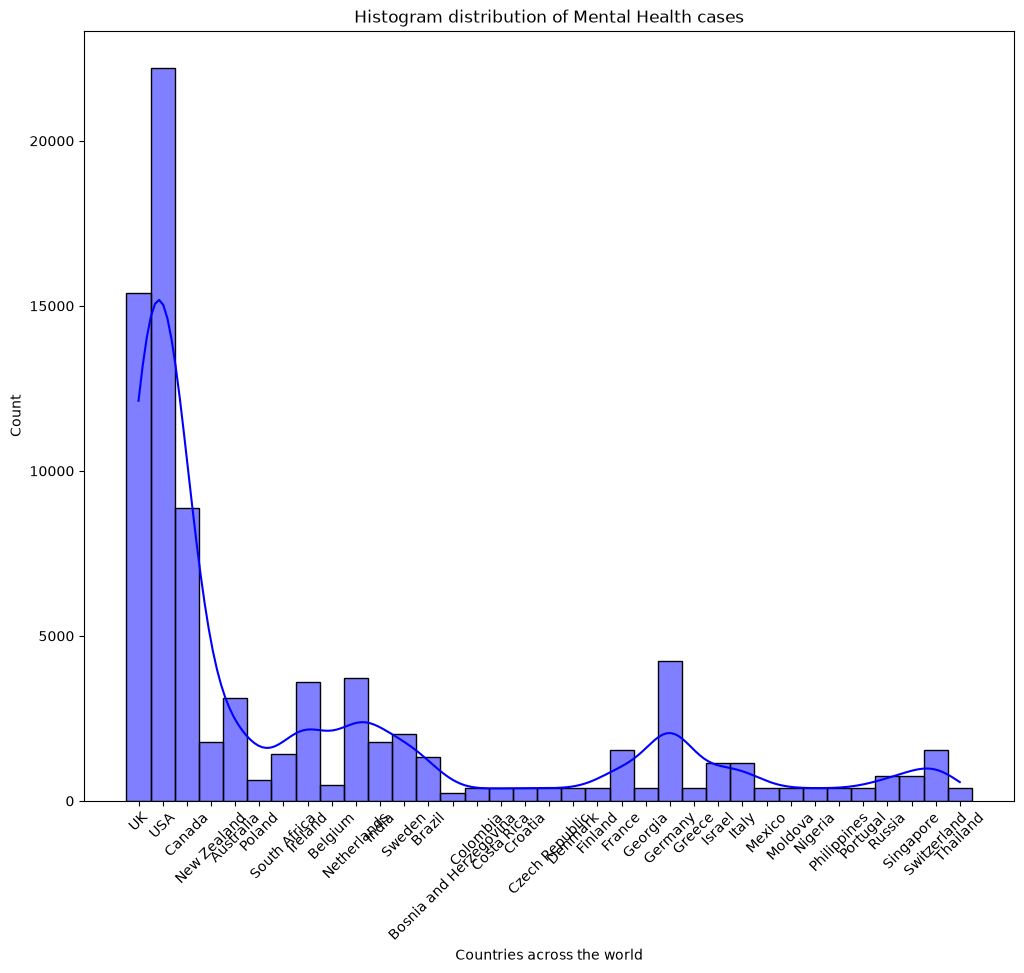

In [16]:
#plotting a histogram
plt.figure(figsize=(12,10))
sns.histplot(x="Country",color="blue",kde=True,data=fd)
plt.title("Histogram distribution of Mental Health cases")
plt.xlabel("Countries across the world")
plt.xticks(rotation=45)
plt.show()

- USA ,followed by UK,then Canada have the highest count of cases with the mental health challenges across the sammpled countries in the world
- Brazil has the lowest count of cases on mental health challenges across the sampled world countries

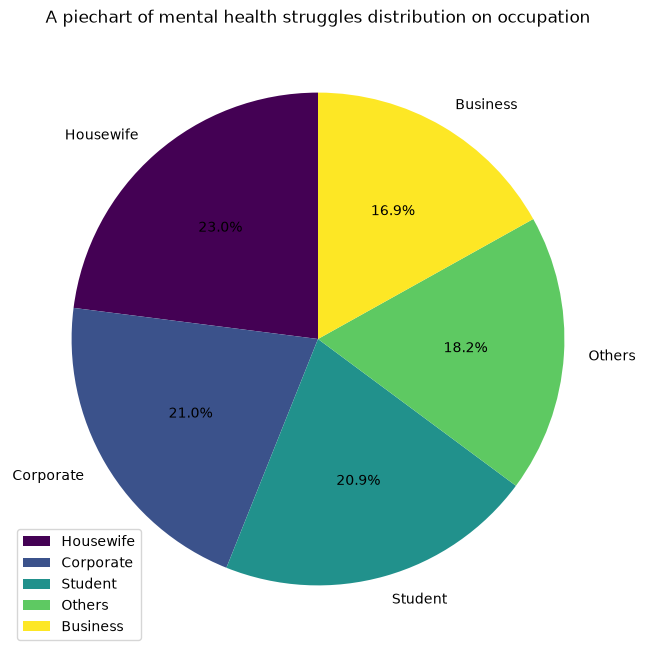

In [17]:
#plotting a piechart
plt.figure(figsize=(8,8))
case=fd["Occupation"].value_counts()
case.plot(kind="pie",autopct="%1.1f%%",startangle=90,cmap="viridis")
plt.title("A piechart of mental health struggles distribution on occupation")
plt.legend()
plt.show()

- Business people experience lowest case count of mental health challenges.
- people in Housewife occupation experience the highest case count of the mental health challenges.

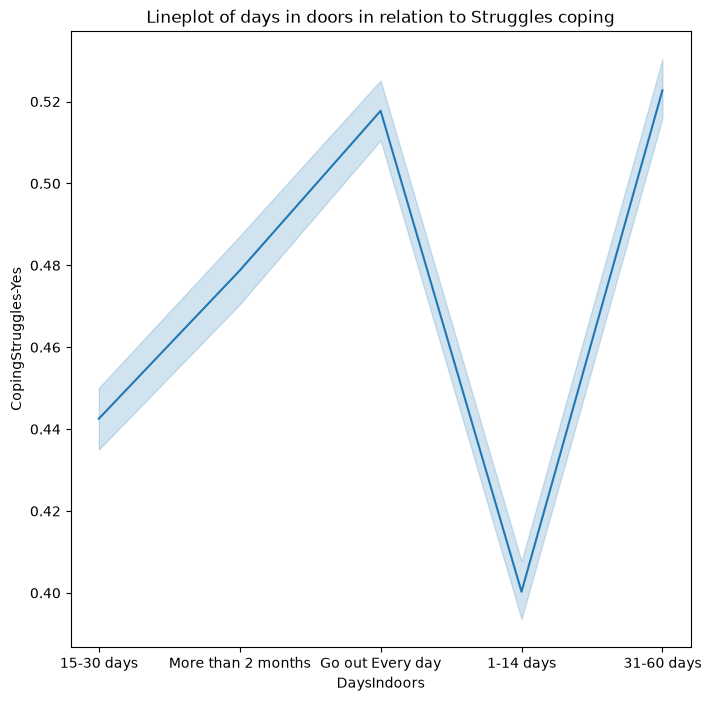

In [18]:
fd["CopingStruggles_Yes"]=(fd["CopingStruggles"]=="Yes").astype(int)
fd[["CopingStruggles","CopingStruggles_Yes"]].head()
#plottig a lineplot
plt.figure(figsize=(8,8))
sns.lineplot(x="DaysIndoors",y="CopingStruggles_Yes",data=fd)
plt.title("Lineplot of days in doors in relation to Struggles coping")
plt.xlabel("DaysIndoors")
plt.ylabel("CopingStruggles-Yes")
plt.show()

- people going out every day after Treatment experience a higher count in coping with their mental health struggles
- people staying 1 - 14 days Indoors experience a lower count in coping with their mental health struggles

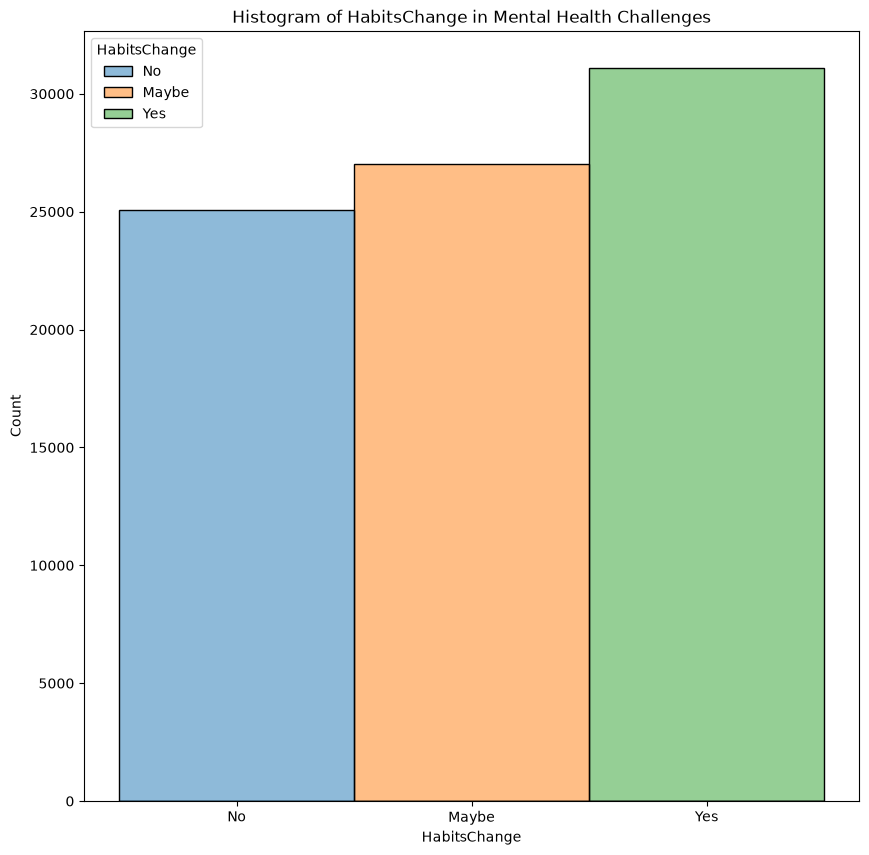

In [19]:
plt.figure(figsize=(10,10))
sns.histplot(x="HabitsChange",alpha=0.5,hue="HabitsChange",edgecolor="black",data=fd)
plt.xlabel("HabitsChange")
plt.ylabel("Count")
plt.title("Histogram of HabitsChange in Mental Health Challenges")
plt.show()

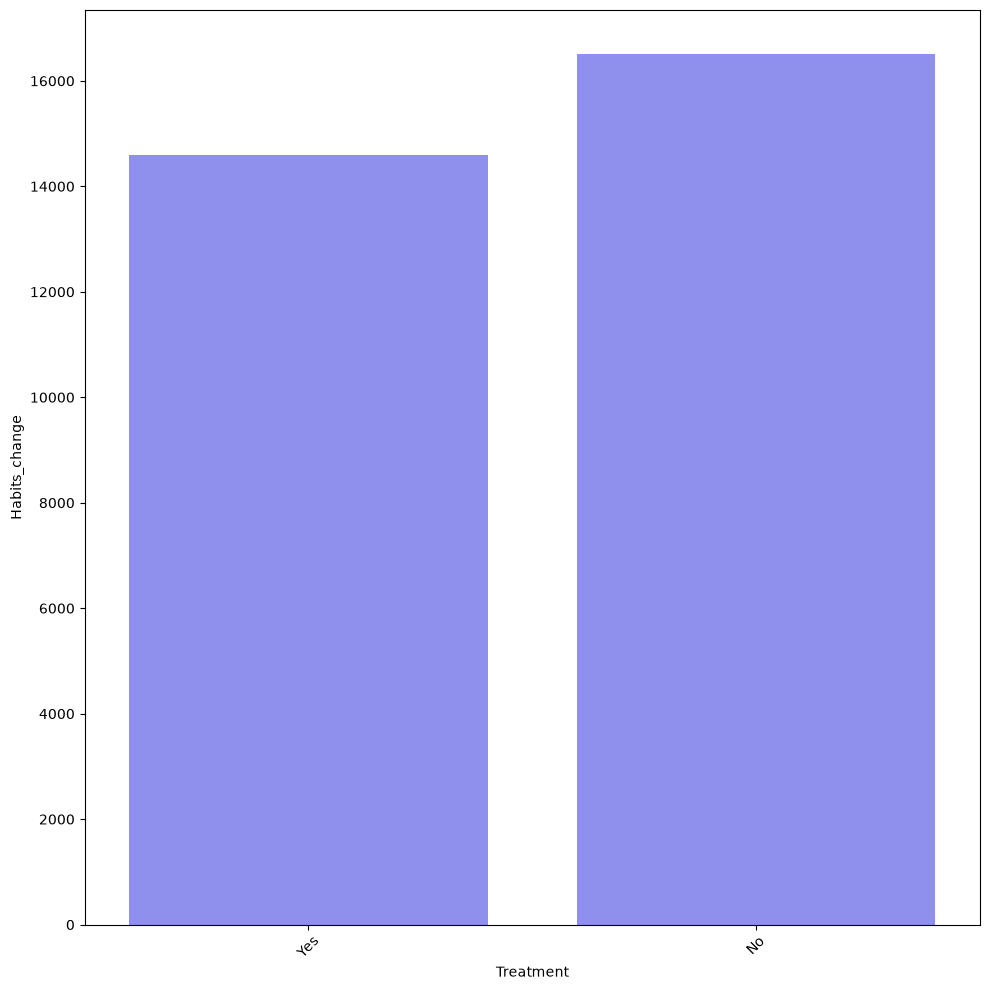

In [20]:
hbc=fd[fd["HabitsChange"]=="Yes"]
plt.figure(figsize=(10,10))
sns.countplot(data=hbc,x="Treatment",color="blue",alpha=0.5)
plt.xlabel("Treatment")
plt.ylabel("Habits_change")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


- people undergoing mental health Treatment have a lesser count in the habits change on mental health challenge.
- people failing to take mental health treatment have a higher count in the habits change on mental health challenge.

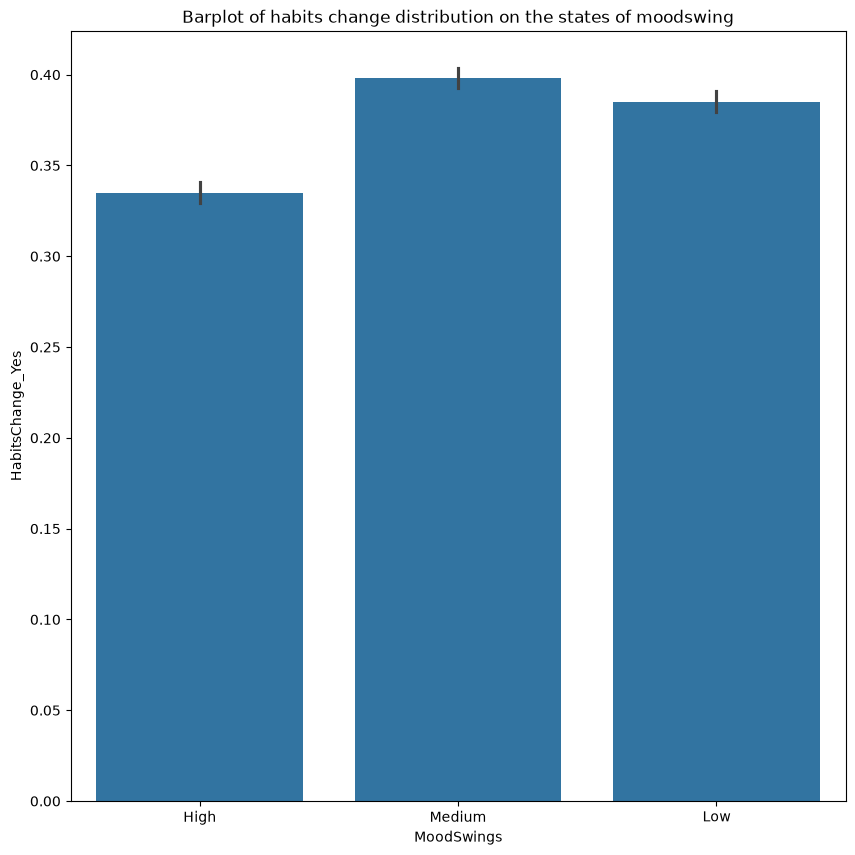

In [21]:
#plotting a barplot
fd["HabitsChange_Yes"]=(fd["HabitsChange"]=="Yes").astype(int)
fd[["HabitsChange","HabitsChange_Yes"]].head()
plt.figure(figsize=(10,10))
sns.barplot(x="MoodSwings",y="HabitsChange_Yes",data=fd)
plt.title("Barplot of habits change distribution on the states of moodswing")
plt.show()

- Medium moodswing,followed by Low moodswing experience largest count in the habits change on mental health struggles.
- High moodswing exprience the smallest count in habits change on mental health struggles.

In [22]:
from sklearn.preprocessing import LabelEncoder
#selecting relevant columns
use_columns=["SelfEmployed","FamilyHistory","Treatment","DaysIndoors","HabitsChange","MentalHealthHistory","IncreasingStress","MoodSwings","SocialWeakness","CopingStruggles","WorkInterest","MentalHealthInterview","CareOptions"]
#copying sected columns
data=fd[use_columns].copy()
#encoding selected categorical data
label_encoders={}
for col in data.select_dtypes(include=["object","category","string"]):
    encoder=LabelEncoder()
    data[col]=encoder.fit_transform(data[col])
    label_encoders[col]=encoder
#convert Boolean columns to int
for col in data.select_dtypes(include=["bool"]).columns:
    data[col]=data[col].astype(int)


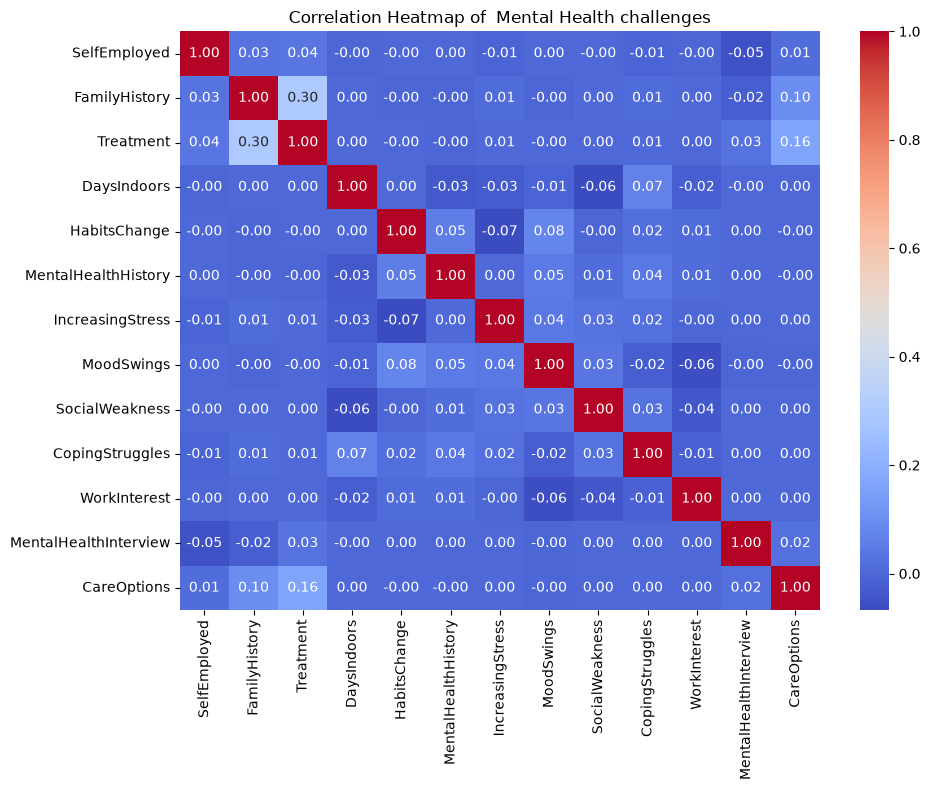

In [23]:
plt.figure(figsize=(10, 8))
#calculating correlation
correlation_matrix=data.corr(method="pearson")
#plotting heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of  Mental Health challenges")
plt.tight_layout()
plt.show()

- FamilyHistory in mental health concerns is weakly correlated to the Treatment ,which can
 be used to somehow to predict whether the patient requires treatment or not.
- Treatment is weakly correlated to the careoptons in the mental health challenges

## Conclusions
- Most individuals under mental health struggles allowed move out every, cope with their mental struggles.
- Of the recorded occupations ,Housewife indulging people have the highest count in the mental health records.
- FamilyHistory on mental health struggles is moderately weakly correlated to the treatment thus can be used to predict whether the patient needs treatment or not depending on the instance.
## Recommendations
- Psychiatrists should employ "every day out" to the capable group of mental health patients to cope with their struggles.
- Housewives should be handled by their employers considerably on balancing their own families affairs and work affairs.
- The correspondence of Family History and the treatment of the mental health challenge should be taken keenly as far as coping with it's struggles is of concern.

## Mental Health Treatment Recommendation modelling

In [24]:
#importing the necessary libraries
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score,precision_score,f1_score,recall_score
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,classification_report

In [25]:
#dropping the target
X=fd.drop(columns=["Treatment"])
y=fd["Treatment"]
#encoding string values to numeric
X_encoded=pd.get_dummies(X,drop_first=True)
y_encoded=y.map({"Yes":1,"No":0})
le=LabelEncoder()
y_encoded=le.fit_transform(y)

In [26]:
y.unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [27]:
#train_test_split
X_train,X_test,y_train,y_test=train_test_split(X_encoded,y_encoded,test_size=0.2,random_state=42)

### Logistic Regression

In [28]:
#instanstiating the model
lr=LogisticRegression(max_iter=1000)


In [29]:
dup_cols=X_train.columns[X_train.columns.duplicated()]
print(dup_cols)

Index(['HabitsChange_Yes', 'CopingStruggles_Yes'], dtype='str')


In [30]:
#removing duplicate columns from the trained data
X_train=X_train.loc[:,~X_train.columns.duplicated()]
X_test=X_test.loc[:,~X_test.columns.duplicated()]

In [31]:
#fit the trained model
lr.fit(X_train,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [32]:
#predict
y_pred_lr=lr.predict(X_test)

In [33]:
#valuation metrics
print("  Logistic Regression")
print("Acuracy  :",accuracy_score(y_test,y_pred_lr))
print("Precision:",precision_score(y_test,y_pred_lr))
print("F1score  :",f1_score(y_test,y_pred_lr))
print("Recall   :",recall_score(y_test,y_pred_lr))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred_lr))
print("Classification_report:",classification_report(y_test,y_pred_lr))

  Logistic Regression
Acuracy  : 0.7055535521096286
Precision: 0.6924481544280684
F1score  : 0.6842817554939743
Recall   : 0.6763057324840764
Confusion Matrix: [[6430 2358]
 [2541 5309]]
Classification_report:               precision    recall  f1-score   support

           0       0.72      0.73      0.72      8788
           1       0.69      0.68      0.68      7850

    accuracy                           0.71     16638
   macro avg       0.70      0.70      0.70     16638
weighted avg       0.71      0.71      0.71     16638



### RandomForest

In [34]:
from sklearn.ensemble import RandomForestClassifier
# instanstiating the model
model=RandomForestClassifier(n_estimators=200,random_state=42,max_depth=5)
#fit the trained model
model.fit(X_train,y_train)
y_pred_rf=model.predict(X_test)



In [35]:
print("   RandomForest Clasification")
print("Accuracy :",accuracy_score(y_test,y_pred_rf))
print("Precision:",precision_score(y_test,y_pred_rf))
print("F1score  :",f1_score(y_test,y_pred_rf))
print("Recall   :",recall_score(y_test,y_pred_rf))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred_rf))
print("Classification_report:",classification_report(y_test,y_pred_rf))

   RandomForest Clasification
Accuracy : 0.6967784589493929
Precision: 0.6931552127806088
F1score  : 0.6661372510091986
Recall   : 0.6411464968152866
Confusion Matrix: [[6560 2228]
 [2817 5033]]
Classification_report:               precision    recall  f1-score   support

           0       0.70      0.75      0.72      8788
           1       0.69      0.64      0.67      7850

    accuracy                           0.70     16638
   macro avg       0.70      0.69      0.69     16638
weighted avg       0.70      0.70      0.70     16638



Text(0.5, 1.0, 'Confusion matrix RandomForest')

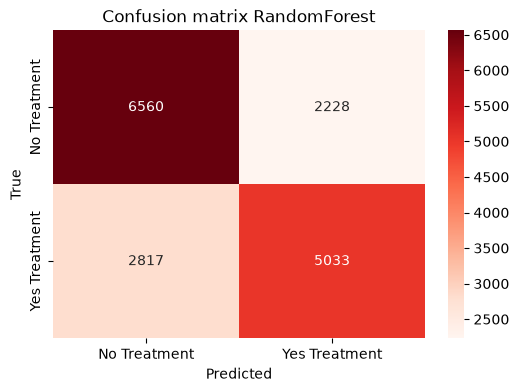

In [36]:
#plottig the confusion matrix
cm_forest=confusion_matrix(y_test,y_pred_rf)
labels=["No Treatment","Yes Treatment"]
plt.figure(figsize=(6,4))
sns.heatmap(cm_forest,annot=True,fmt="d",cmap="Reds",xticklabels=labels,yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix RandomForest")

### Decision Tree

In [37]:
from sklearn.tree import DecisionTreeClassifier
#instantiating ds model
ds= DecisionTreeClassifier(
criterion="gini",
max_depth=3,
random_state=42
)
X_train=X_train.loc[:,~X_train.columns.duplicated()]
X_test=X_test.loc[:,~X_test.columns.duplicated()]
ds.fit(X_train, y_train)
y_pred = ds.predict(X_test)
print("  Decision Trees")
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:",precision_score(y_test,y_pred))
print("F1score  :",f1_score(y_test,y_pred))
print("Recall   :",recall_score(y_test,y_pred))
print("Confusion Matrix:",confusion_matrix(y_test,y_pred))
print("Classification_report:",classification_report(y_test,y_pred))

  Decision Trees
Accuracy : 0.6848779901430461
Precision: 0.6411478072550081
F1score  : 0.6931226221832016
Recall   : 0.7542675159235669
Confusion Matrix: [[5474 3314]
 [1929 5921]]
Classification_report:               precision    recall  f1-score   support

           0       0.74      0.62      0.68      8788
           1       0.64      0.75      0.69      7850

    accuracy                           0.68     16638
   macro avg       0.69      0.69      0.68     16638
weighted avg       0.69      0.68      0.68     16638



In [ ]:
#comparing classifying models
results =pd.DataFrame({"Model":["Logistic Regression","Random Forest","Decision Tree"],
                       "Accuracy":[accuracy_score(y_test,y_pred_lr),

                        accuracy_score(y_test,y_pred_rf),
                        accuracy_score(y_test,y_pred)
                          ],
                     "Precision":
                           [precision_score(y_test,y_pred_lr),

                            precision_score(y_test,y_pred_rf),
                            precision_score(y_test,y_pred)
                            ],
                            "Recall":[recall_score(y_test,y_pred_lr),
                                      recall_score(y_test,y_pred_rf),
                                      recall_score(y_test,y_pred)
                                      ],
                            "F1 score":[f1_score(y_test,y_pred_lr),
                                        f1_score(y_test,y_pred_rf),
                                        f1_score(y_test,y_pred)],          
})
print(results)

                 Model  Accuracy  Precision    Recall  F1 score
0  Logistic Regression  0.705554   0.692448  0.676306  0.684282
1        Random Forest  0.696778   0.693155  0.641146  0.666137
2        Decision Tree  0.684878   0.641148  0.754268  0.693123


## Conclusions
- The reliability of the logistic regression model is around 70% which is relatively closer to the right prediction.
- Based on the confusion matrix plot the True Negative has a higher correlation compared to the True positive , the focus
  should be on predicting "No Treatment".
- Decision tree model have a recall of around 75% ,that's the predictons that really belonged to the right class.
## Recommendations
-